In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [5]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'


In [7]:
df = pd.read_csv(data)

In [8]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [24]:
df.dtypes
categorical = ['lead_source','industry','employment_status','location']
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']


In [25]:

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [26]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [40]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

# Q1

In [42]:
from sklearn.metrics import roc_auc_score

full_AUC = []

for c in numerical:
    AUC = roc_auc_score(y_train, df_train[c])
    full_AUC.append(AUC)
    invertida = AUC < 0.5
    if invertida:
        AUC = roc_auc_score(y_train, -df_train[c])
    print(c, round(AUC, 3), invertida)

    


annual_income 0.608 False
number_of_courses_viewed 0.723 False
interaction_count 0.765 False
lead_score 0.788 False


#### lead_score has highest AUC

# Q2

In [49]:
dicts = df_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
   
   

LogisticRegression(max_iter=1000, solver='liblinear')

In [61]:
dicts_val = df_val[categorical + numerical].to_dict(orient='records')


X_val = dv.transform(dicts_val)
y_pred = model.predict_proba(X_val)[:, 1] 
AUC = round(roc_auc_score(y_val, y_pred),3)
AUC

np.float64(0.732)

#### AUC on the validation set is 0.732

# Q3

In [66]:
converted_decision = (y_pred >= 0.5)


In [78]:
thresholds = np.arange(0, 1.01, 0.01)
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

scores = []
for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    r = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    scores.append((t, tp, fp, fn, tn, p, r))
df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall'])


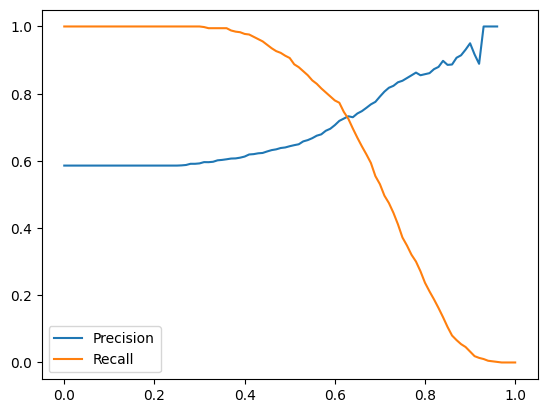

In [79]:
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.legend()

In [84]:
df_scores['diff'] = (df_scores['precision'] - df_scores['recall']).abs()
df_scores.loc[df_scores['diff'].idxmin()]

threshold      0.630000
tp           425.000000
fp           155.000000
fn           161.000000
tn           259.000000
precision      0.732759
recall         0.725256
diff           0.007503
Name: 63, dtype: float64

#### threshold with the smallest absolute diference is 0.63

# Q4 

In [90]:
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])

df_scores.loc[df_scores['f1'].idxmax()]

threshold      0.410000
tp           572.000000
fp           352.000000
fn            14.000000
tn            62.000000
precision      0.619048
recall         0.976109
diff           0.357062
f1             0.757616
Name: 41, dtype: float64

#### threshold 0.41 for max F1

# Q5

In [91]:
from sklearn.model_selection import KFold

In [92]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [93]:
dv, model = train(df_train, y_train)

In [94]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [95]:
y_pred = predict(df_val, dv, model)

In [98]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(' %.3f +- %.3f' % ( np.mean(scores), np.std(scores)))

 0.732 +- 0.007


#### std is 0.007

# Q6  

In [100]:
from tqdm.auto import tqdm
from sklearn.model_selection import KFold

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

resultados = []

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred = predict(df_va, dv, model)

        scores.append(roc_auc_score(y_va, y_pred))

    media = round(np.mean(scores), 3)
    desv = round(np.std(scores), 3)
    resultados.append((C, media, desv))
    print('C=%s %.3f +- %.3f' % (C, media, desv))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


#### the best mean auc is when c=0.001